# Phase 2 — Frozen Evaluation Summary

**Read-only analysis.** Uses saved evaluation outputs; does not train, tune, or perform test inference. Run from repository root or notebook directory.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if not (root / "docs/phase-2/evaluation/test-metrics.json").exists():
    root = root.parent
assert (root / "docs/phase-2/evaluation/test-metrics.json").exists(), (
    "Run from repo root or notebooks/"
)
metrics = json.loads((root / "docs/phase-2/evaluation/test-metrics.json").read_text())
protocol = json.loads((root / "docs/phase-2/evaluation/protocol.json").read_text())
print("Models:", list(protocol["models"]))
print("Top-level metric keys:", list(metrics))

Models: ['a2_1_cnn', 'h3_hybrid', 'phase1_svm']
Top-level metric keys: ['classes', 'gradcam_cases', 'gradcam_grid_png', 'mcnemar', 'models', 'phase1_reference', 'robustness', 'sample_count', 'test_predictions_csv', 'test_predictions_sha256']


## Frozen headline results

These figures were recorded by the evaluation team on the 377-image test set. The Phase 1 SVM here is the full-training refit, **not** the historical Phase 1 ensemble.

,Model,Macro F1,Accuracy,ECE
0,A2.1 CNN,0.8577,0.8806,0.0367
1,H3 hybrid,0.9233,0.9363,0.0130
2,Phase 1 SVM (refit),0.8963,0.9019,0.0361


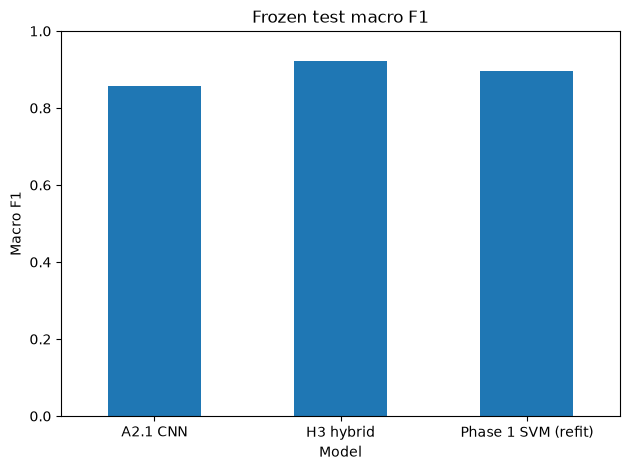

In [2]:
labels = {"phase1_svm": "Phase 1 SVM (refit)", "a2_1_cnn": "A2.1 CNN", "h3_hybrid": "H3 hybrid"}
results = pd.DataFrame(
    [
        {
            "Model": labels[key],
            "Macro F1": data["unconditional"]["macro_f1"],
            "Accuracy": data["unconditional"]["accuracy"],
            "ECE": data["unconditional"]["expected_calibration_error"],
        }
        for key, data in metrics["models"].items()
    ]
)
display(results.round(4))
ax = results.plot.bar(
    x="Model",
    y="Macro F1",
    legend=False,
    ylim=(0, 1),
    rot=0,
    title="Frozen test macro F1",
)
ax.set_ylabel("Macro F1")
plt.tight_layout()
plt.show()

## Pre-registered demo thresholds

Read directly from the frozen protocol; no re-optimization.

In [3]:
thresholds = pd.DataFrame(
    [
        {
            "Model": labels[key],
            "Demo threshold": item["demo_threshold"],
            "Headline threshold": item["headline_threshold"],
        }
        for key, item in protocol["models"].items()
    ]
)
display(thresholds)

,Model,Demo threshold,Headline threshold
0,A2.1 CNN,0.87,0.50
1,H3 hybrid,0.53,0.00
2,Phase 1 SVM (refit),0.76,0.45


## Ablation study (5-fold training CV)

Read from `docs/phase-2/ablations/summary.csv`. A2.1 is the only variant that beats BASE by more than the fold standard deviation.

In [4]:
ablations = pd.read_csv(root / "docs/phase-2/ablations/summary.csv")
columns = ["id", "factor", "description", "mean_macro_f1", "std_macro_f1",
           "median_best_epoch", "trainable_parameters"]
display(ablations[columns].sort_values("mean_macro_f1", ascending=False).round(4))

,id,factor,description,mean_macro_f1,std_macro_f1,median_best_epoch,trainable_parameters
2,A2.1,Fine-Tuning,"MobileNetV2, Last 2 Blocks, 224, Drop 0.2, Aug...",0.8825,0.0219,13,893766
1,A1.1,Architecture,"EfficientNet-B0, Frozen, 224, Drop 0.2, Aug Fu...",0.8557,0.0263,34,7686
0,BASE,Baseline,"MobileNetV2, Frozen, 224, Drop 0.2, Aug Full, ...",0.8515,0.0235,38,7686
4,A4.0,Dropout,"MobileNetV2, Frozen, 224, Drop 0.0, Aug Full, ...",0.8503,0.0226,38,7686
9,A5.4,Augmentation,No Random Rotation,0.8490,0.0208,39,7686
5,A4.2,Dropout,"MobileNetV2, Frozen, 224, Drop 0.5, Aug Full, ...",0.8479,0.0193,40,7686
7,A5.2,Augmentation,No Random Resized Crop,0.8472,0.0243,39,7686
10,A5.5,Augmentation,No Color Jitter,0.8463,0.0234,38,7686
11,A6.1,Imbalance,Class-Weighted Cross-Entropy,0.8453,0.0275,38,7686
8,A5.3,Augmentation,No Horizontal Flip,0.8422,0.0248,37,7686


## McNemar tests on the test set

Read from `test-metrics.json`. Bonferroni threshold: 0.05 / 3 = 0.0167.

In [5]:
mcnemar = pd.DataFrame(
    [{"Comparison": name, **{k: v for k, v in result.items() if not isinstance(v, dict)}}
     for name, result in metrics["mcnemar"].items()]
)
display(mcnemar)

,Comparison,a_only_correct,alpha,b_only_correct,bonferroni_alpha,both_correct,both_wrong,discordant_total,model_a,model_b,n_samples,p_value,significant_bonferroni,significant_unadjusted
0,a2_1_cnn_vs_phase1_svm,25,0.05,33,0.016667,307,12,58,a2_1_cnn,phase1_svm,377,0.358143,False,False
1,h3_hybrid_vs_a2_1_cnn,23,0.05,2,0.016667,330,22,25,h3_hybrid,a2_1_cnn,377,0.000019,True,True
2,h3_hybrid_vs_phase1_svm,23,0.05,10,0.016667,330,14,33,h3_hybrid,phase1_svm,377,0.035082,False,True


## McNemar interpretation and limitations

- H3 vs A2.1: exact p ≈ 0.000019, significant at Bonferroni α = 0.0167.
- H3 vs refit SVM: p ≈ 0.0351, **not** significant after correction.
- The 12-image Grad-CAM sample cannot establish background robustness.
- No external robustness set was collected.

test-confusion-h3_hybrid.png


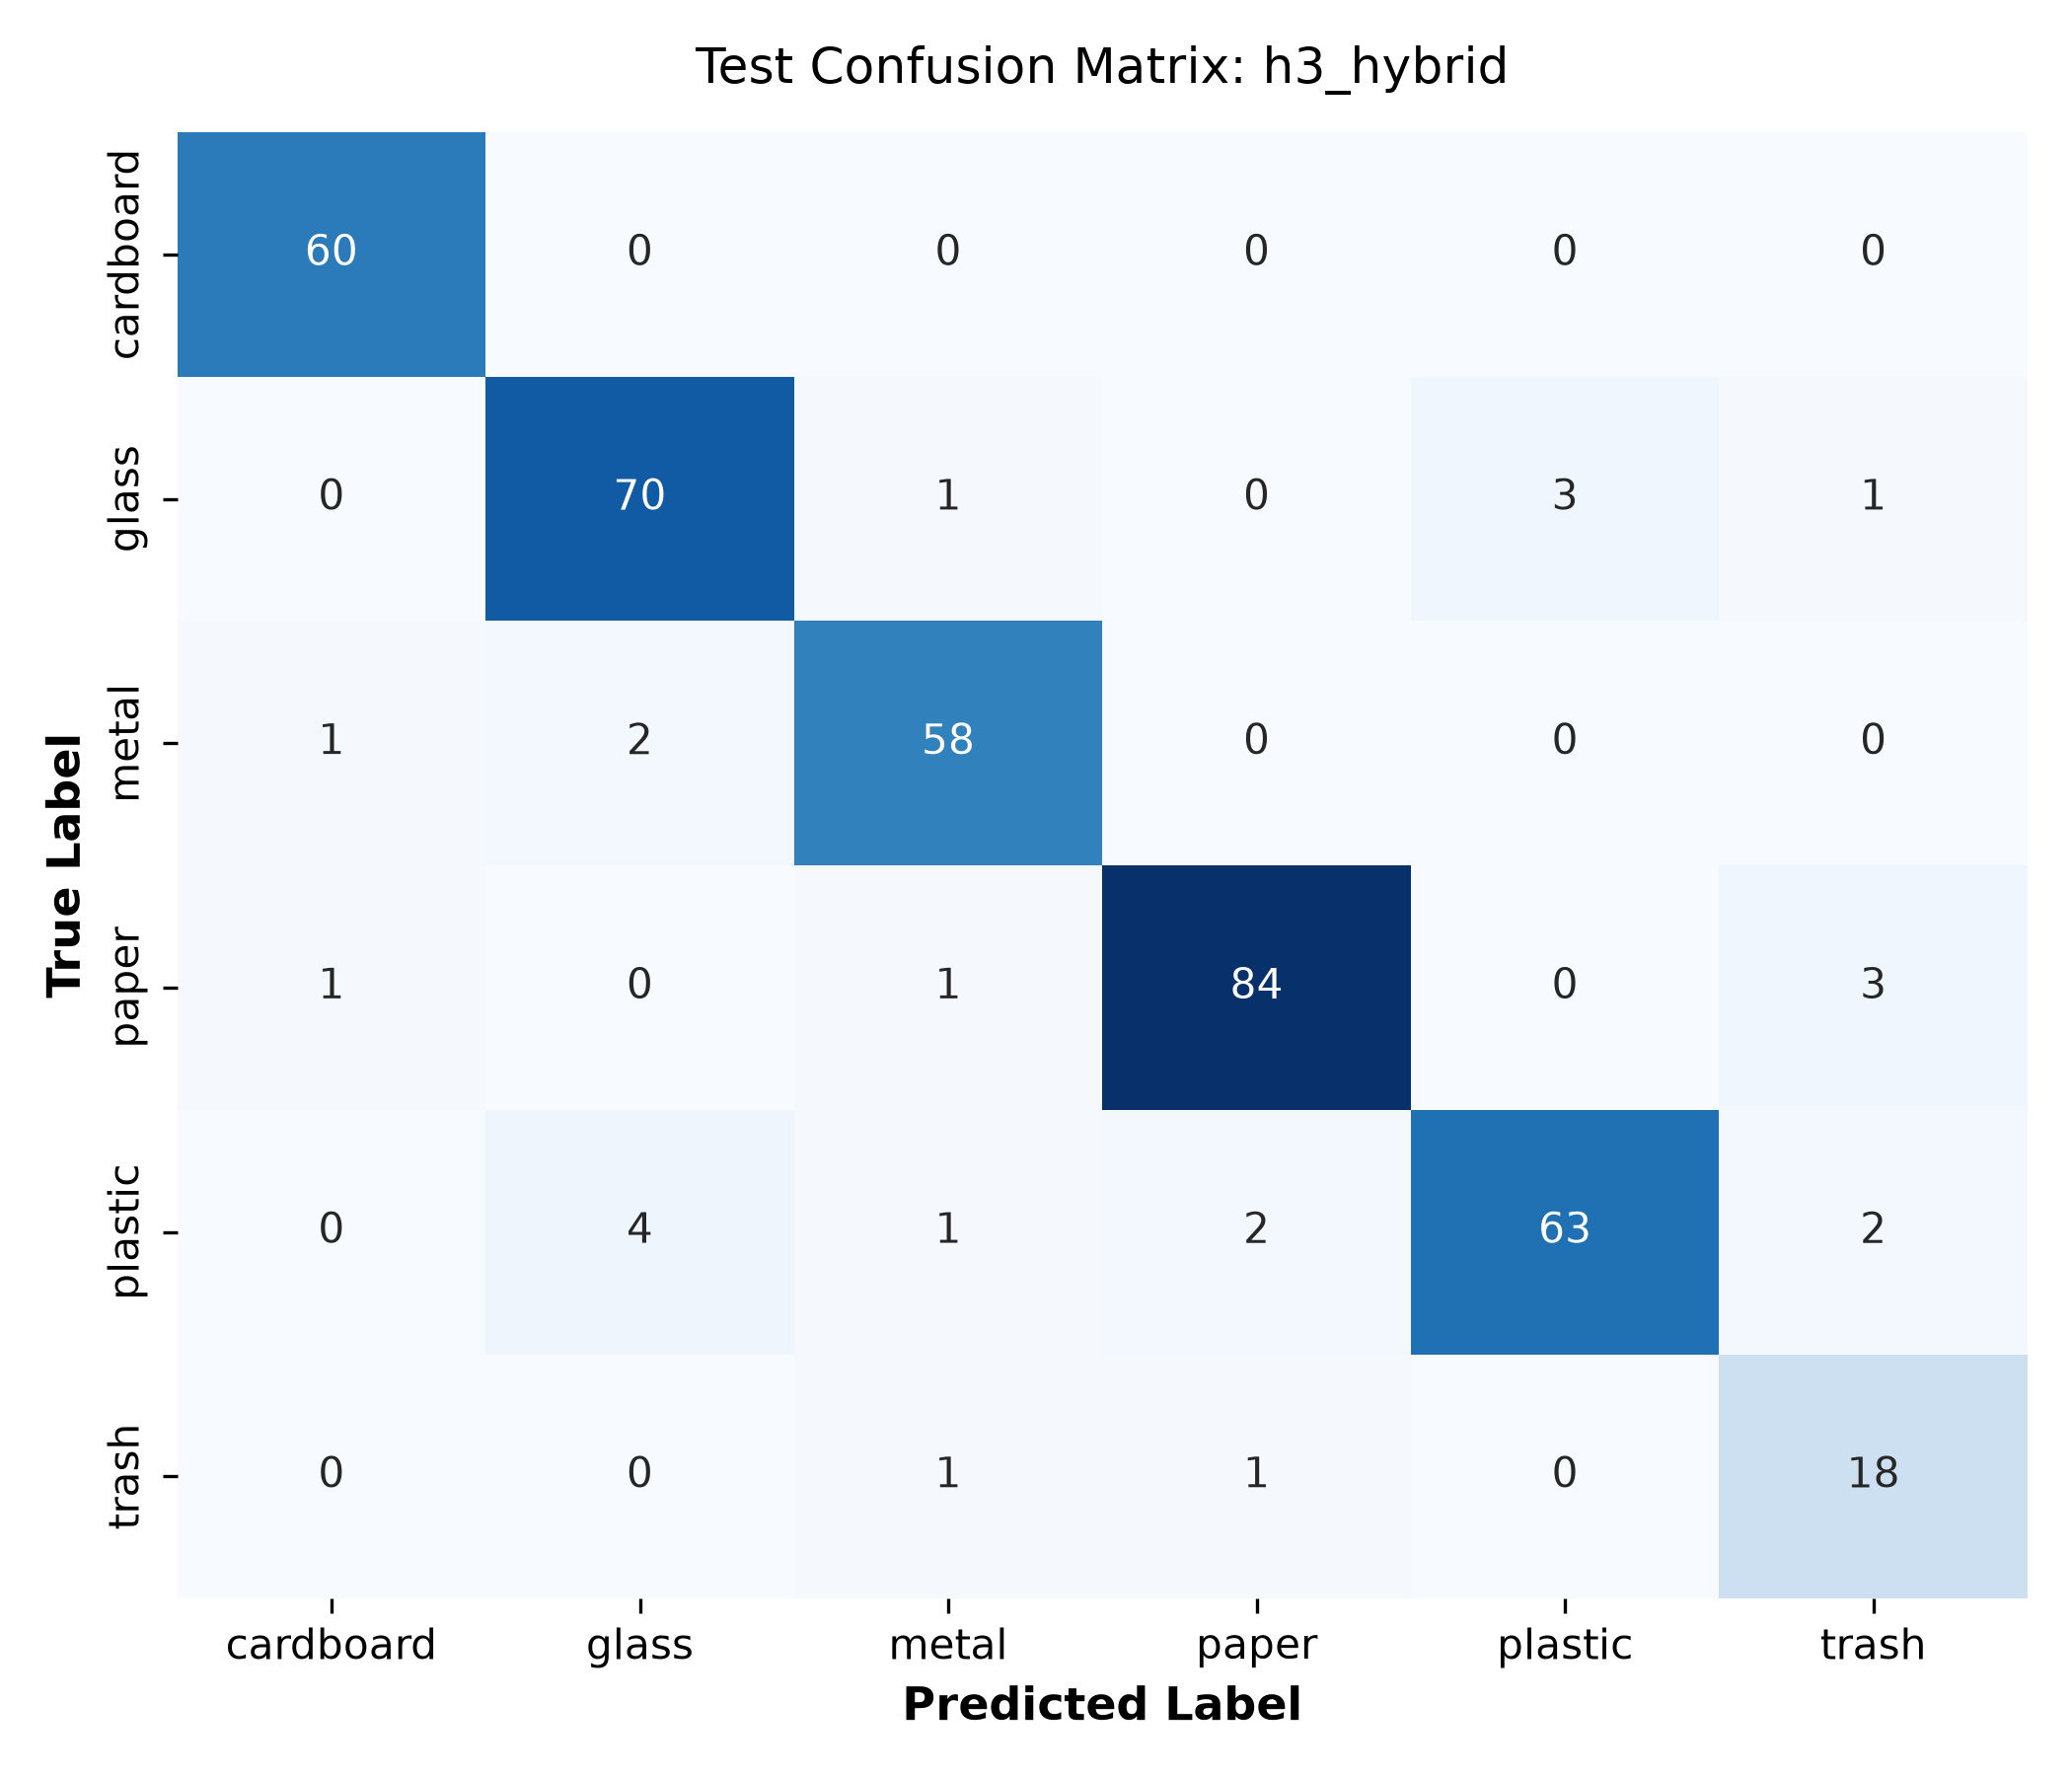

test-reliability-h3_hybrid.png


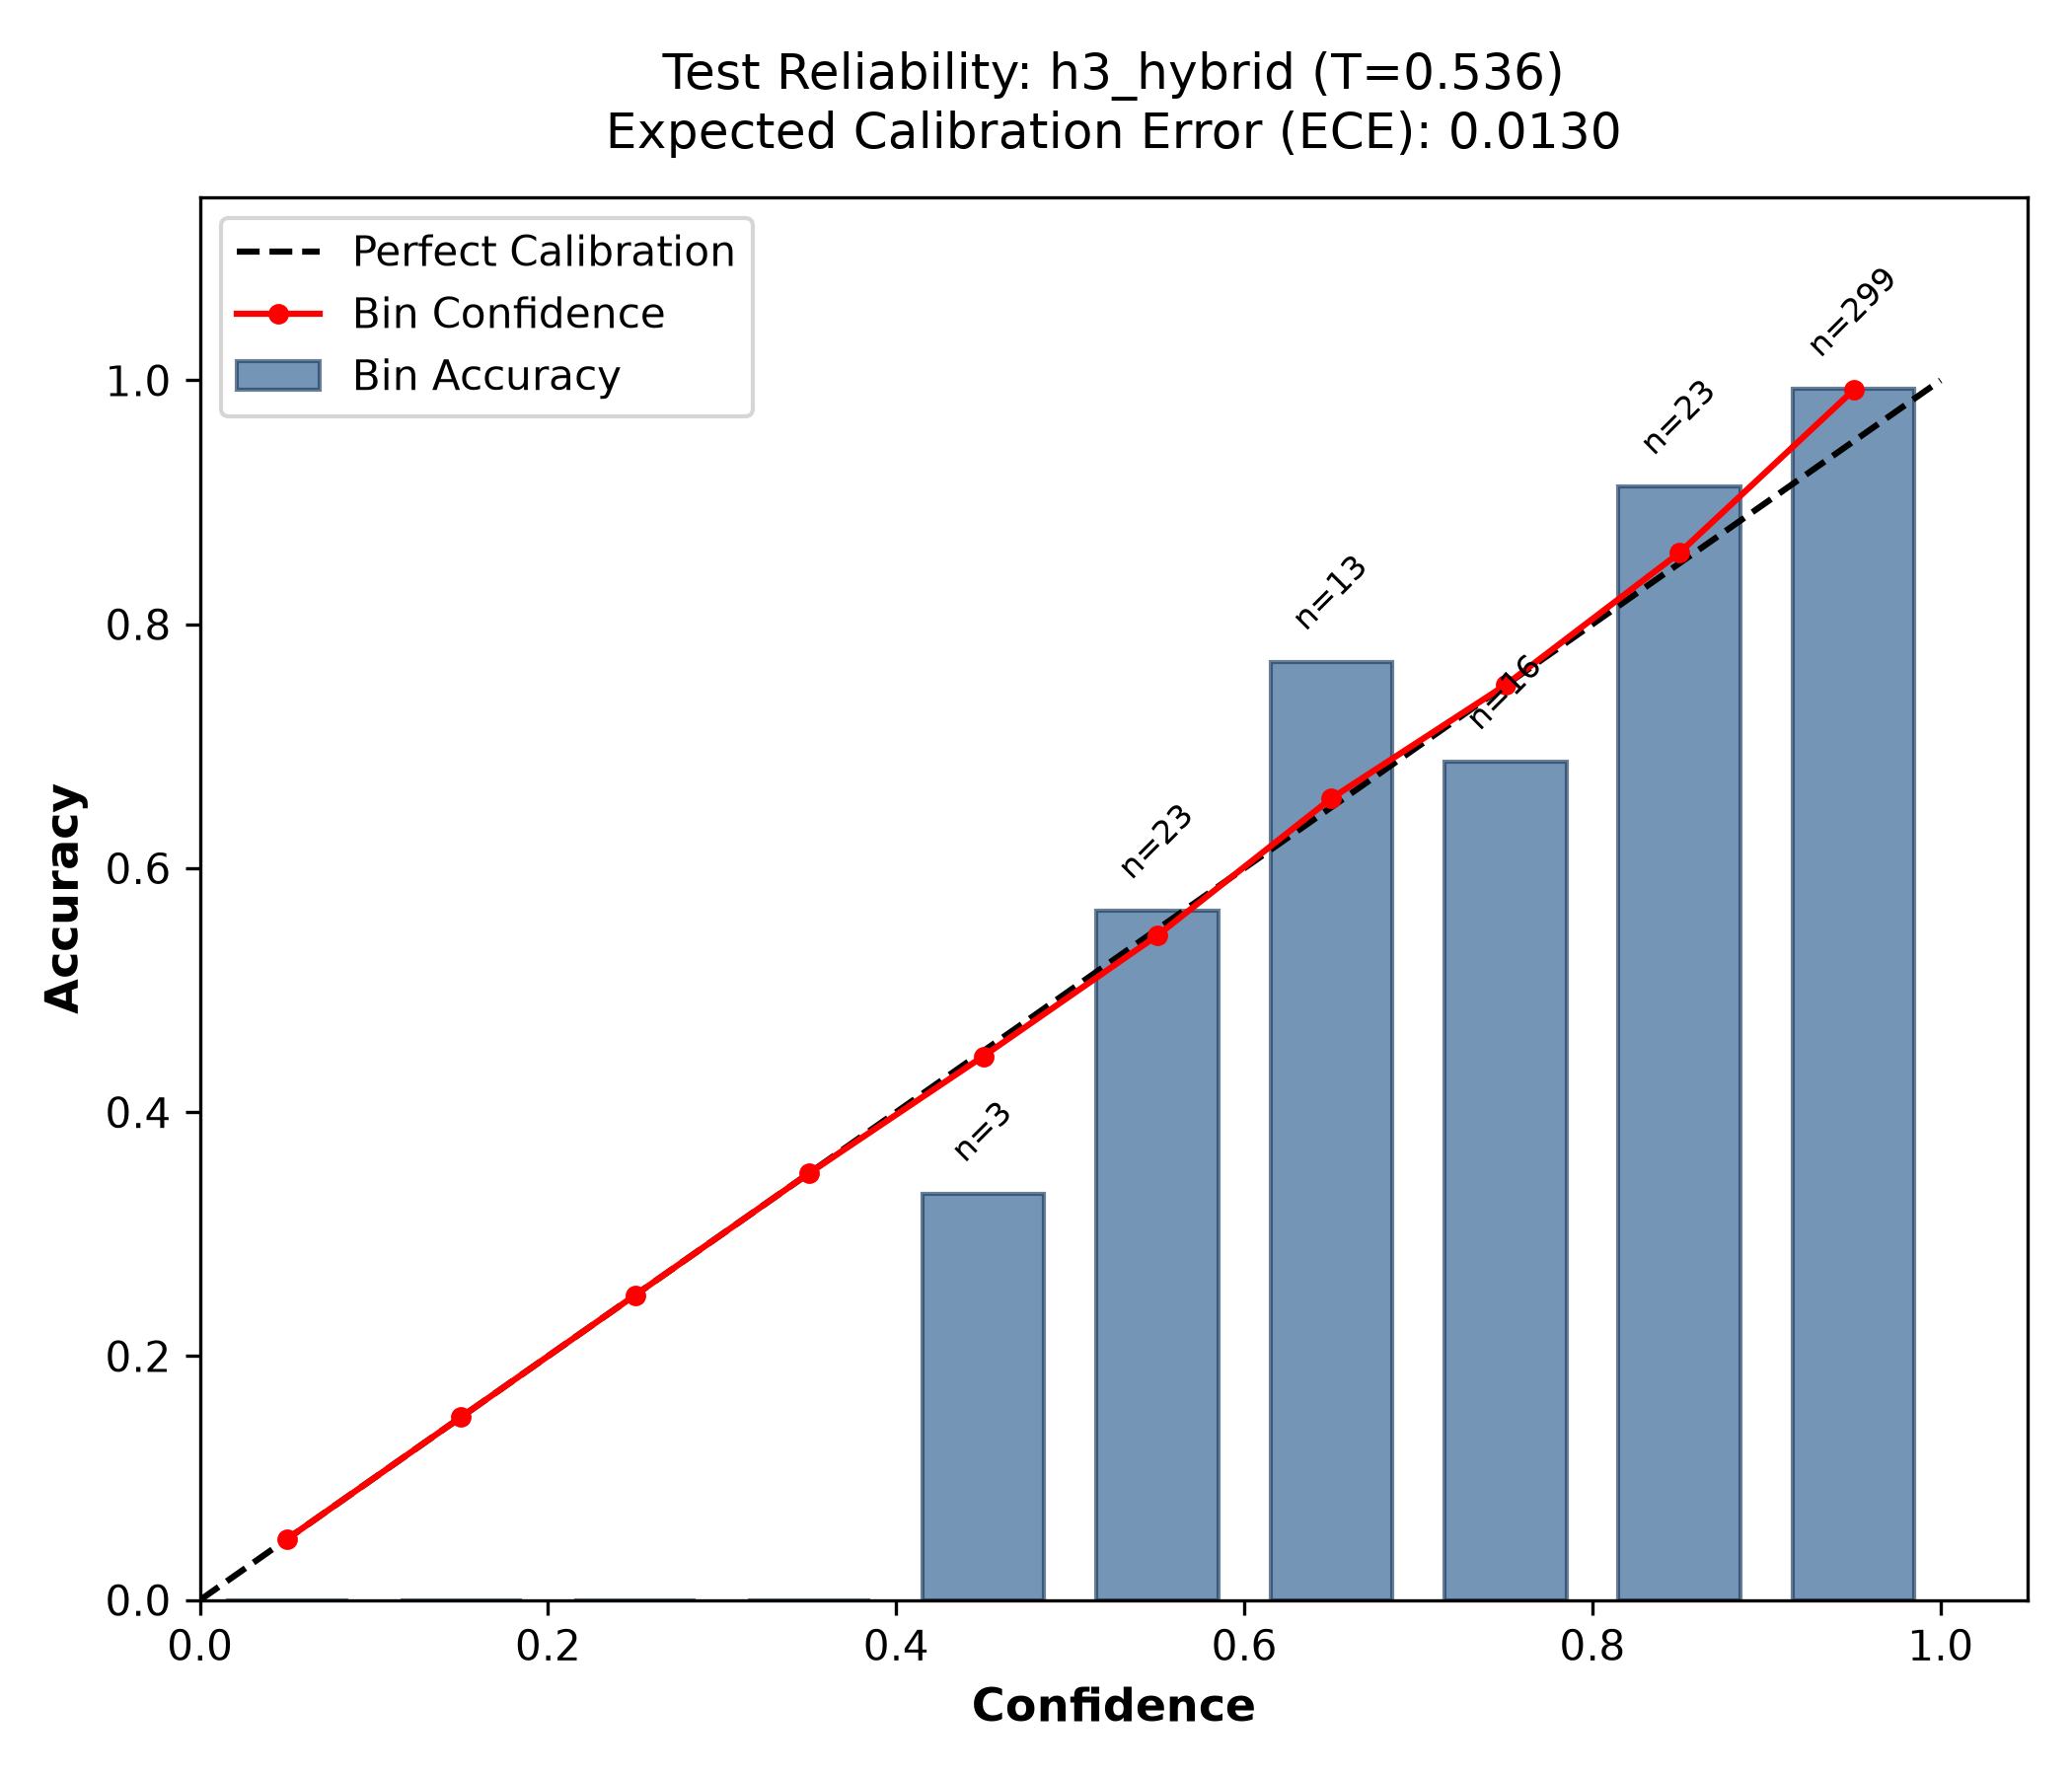

test-gradcam-a2_1_cnn.png


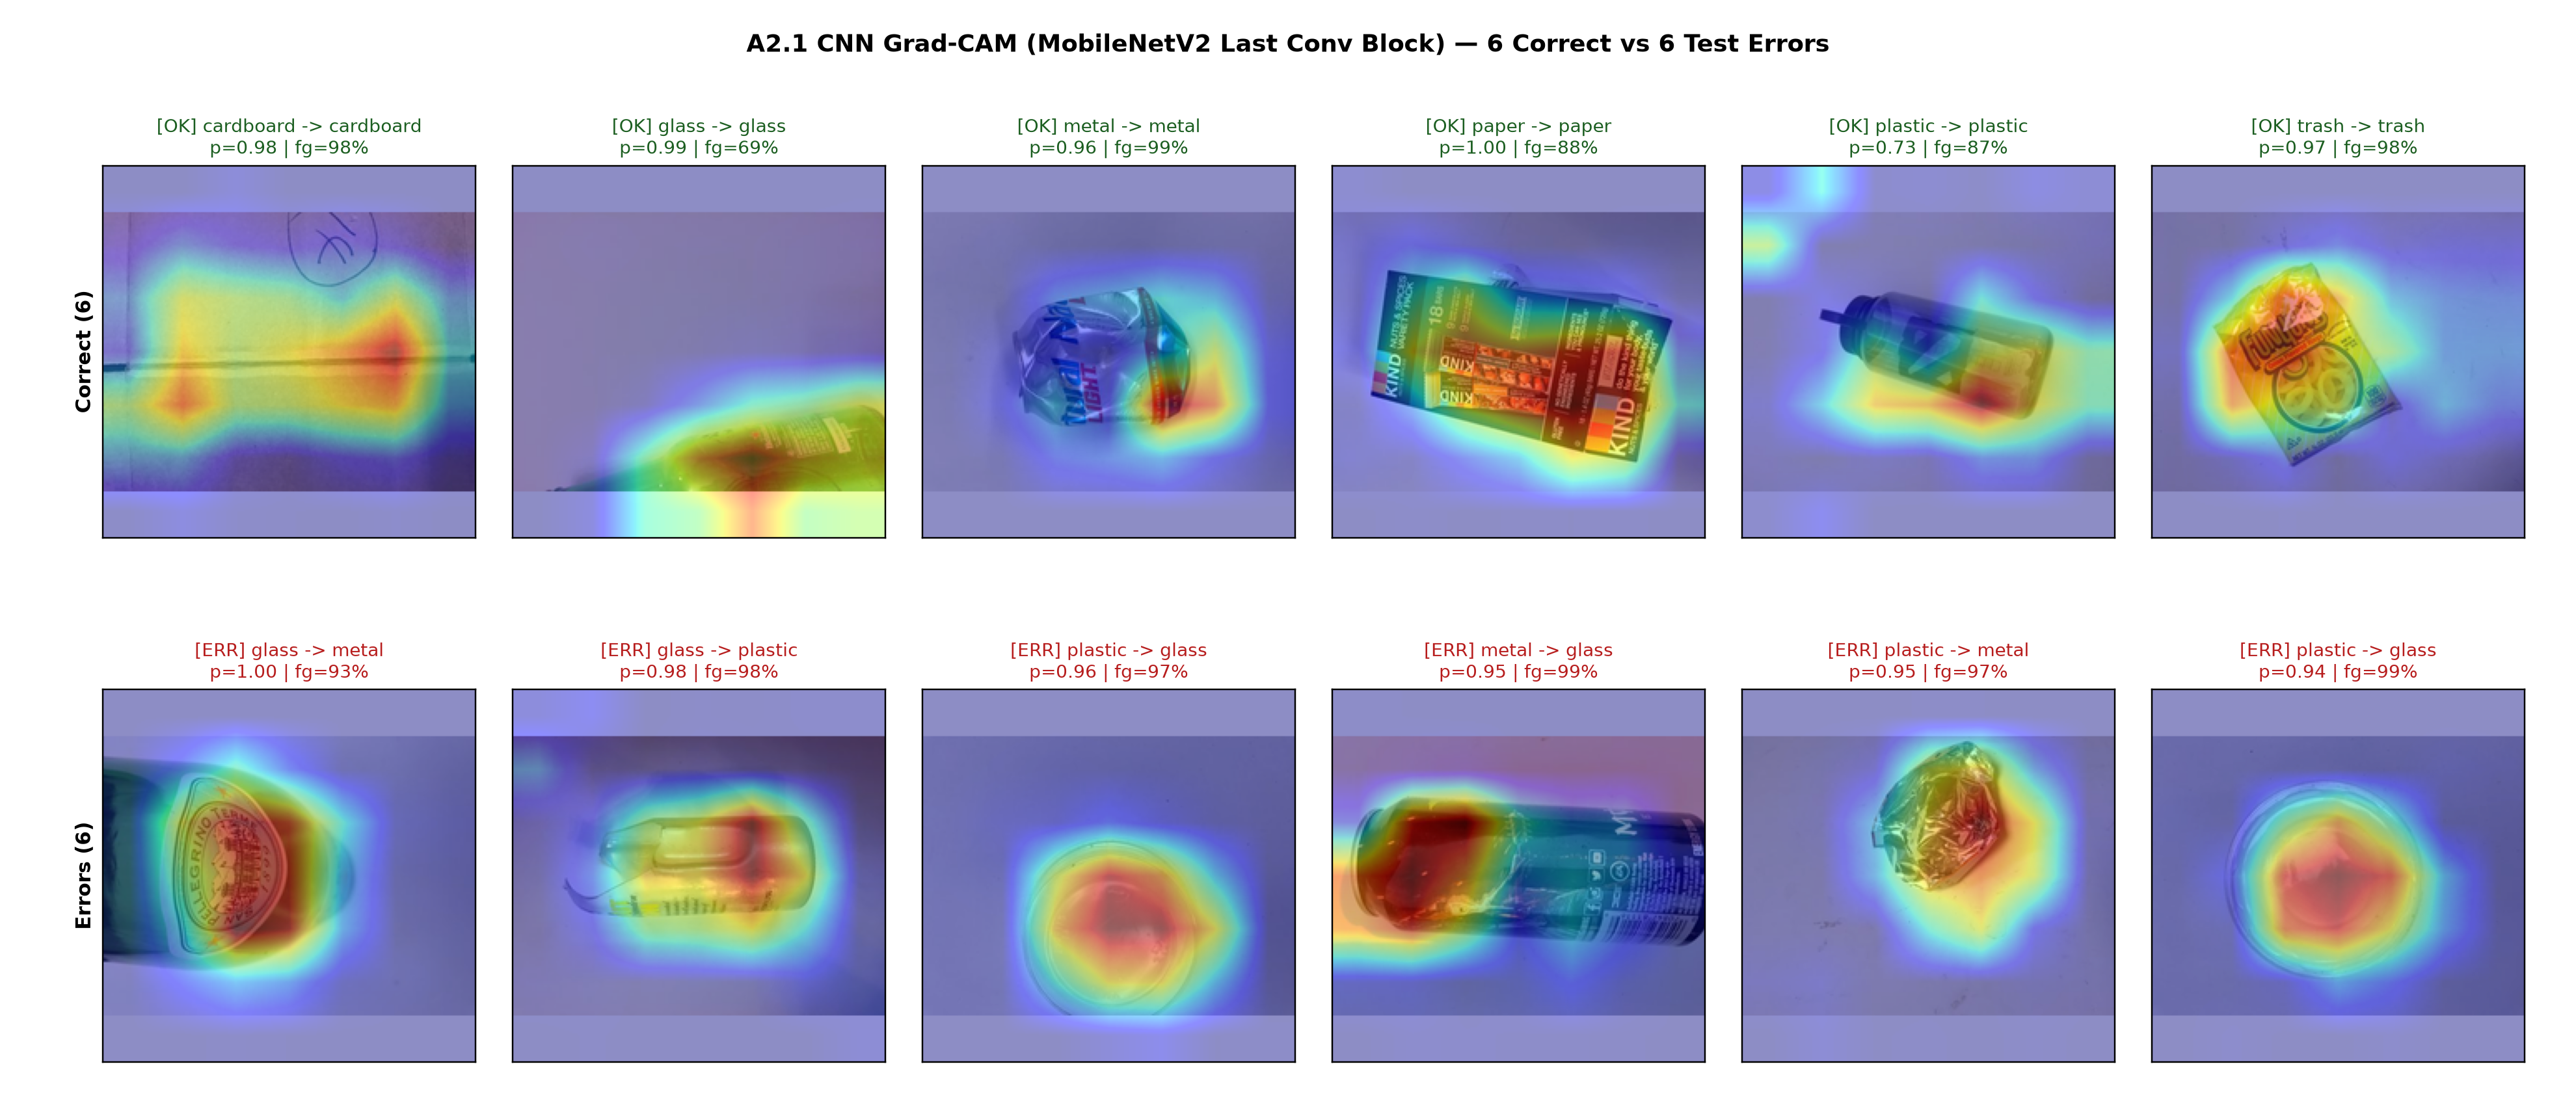

In [6]:
from IPython.display import Image, display

for filename in [
    "test-confusion-h3_hybrid.png",
    "test-reliability-h3_hybrid.png",
    "test-gradcam-a2_1_cnn.png",
]:
    path = root / "docs/phase-2/evaluation" / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path), width=680))